# 02 · Is the calibrated generator realistic?

Three sources of 50-customer instances, all normalised to the unit square the same way the neural
solver normalises real routes:

* **real** – spatially coherent slices of real Amazon routes (`sample_real`);
* **calibrated** – `generate_amazon_like`, parameters fitted in `configs/generator/amazon.json`;
* **uniform** – the Kool et al. distribution every model so far was trained on.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import torch

from neural_routing.data.amazon import AmazonDataset
from neural_routing.data.calibration import project_km
from neural_routing.ml.env import generate
from neural_routing.ml.generators import generate_amazon_like, sample_real

N, COUNT = 50, 1000
FIG = Path("docs/figures")
ds = AmazonDataset("training")
real, real_t = sample_real(project_km(ds.stops), ds.routes["capacity_cm3"], COUNT, N, seed=0)
calib, calib_t = generate_amazon_like(COUNT, N, generator=torch.Generator().manual_seed(0))
unif = generate(COUNT, N, "cvrp", generator=torch.Generator().manual_seed(0))
sources = {"real": real, "calibrated": calib, "uniform": unif}
COLORS = {"real": "#1D9E75", "calibrated": "#D85A30", "uniform": "#888780"}

## 1. What instances look like

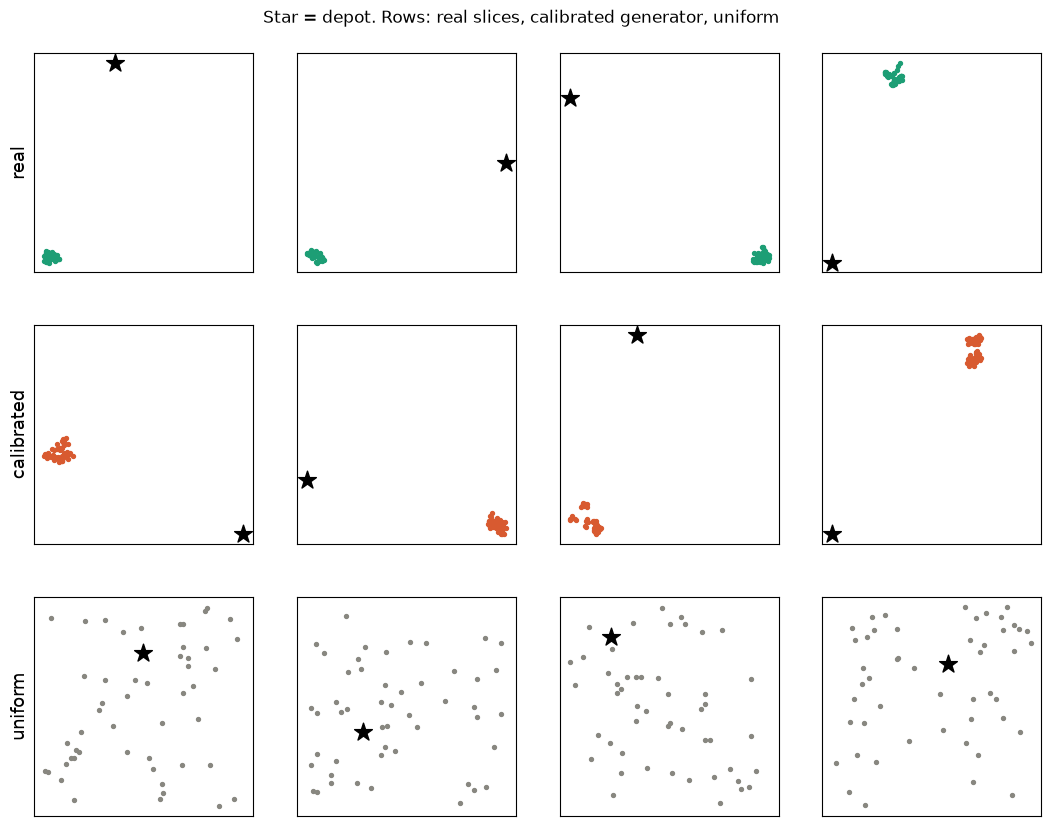

In [2]:
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for row, (name, b) in zip(axes, sources.items(), strict=True):
    for k, ax in enumerate(row):
        xy = b.locs[k].numpy()
        ax.scatter(xy[1:, 0], xy[1:, 1], s=8, c=COLORS[name])
        ax.scatter(xy[0, 0], xy[0, 1], marker="*", s=180, c="k")
        ax.set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05), xticks=[], yticks=[])
        ax.set_aspect("equal")
    row[0].set_ylabel(name, fontsize=13)
fig.suptitle("Star = depot. Rows: real slices, calibrated generator, uniform", y=0.92)
plt.savefig(FIG / "generator_examples.png", dpi=110, bbox_inches="tight")

## 2. Distributions that matter for routing

depot to centroid            real: 1.021  calibrated: 1.007  uniform: 0.395
customer spread              real: 0.031  calibrated: 0.036  uniform: 0.377
nearest-neighbour distance   real: 0.006  calibrated: 0.006  uniform: 0.076
load / capacity              real: 0.243  calibrated: 0.253  uniform: 6.300


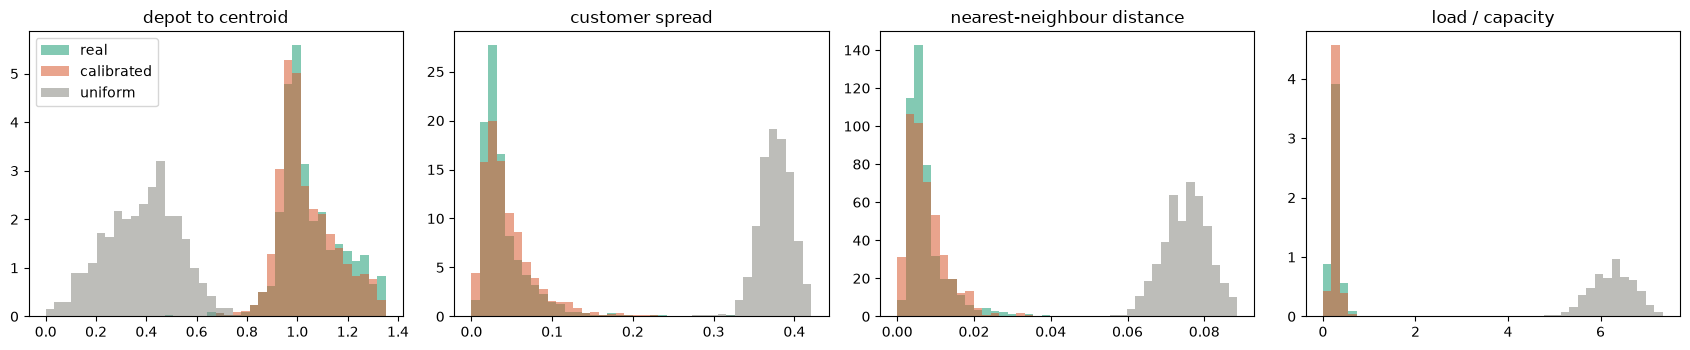

In [3]:
def stats(b):
    cust = b.locs[:, 1:]
    centroid = cust.mean(1)
    d = torch.cdist(cust, cust) + torch.eye(cust.shape[1]) * 9
    return {
        "depot to centroid": (b.locs[:, 0] - centroid).norm(dim=-1),
        "customer spread": (cust - centroid[:, None]).norm(dim=-1).mean(1),
        "nearest-neighbour distance": d.min(-1).values.mean(1),
        "load / capacity": b.demand.sum(1),
    }


S = {k: stats(b) for k, b in sources.items()}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, metric in zip(axes, S["real"], strict=True):
    hi = max(float(torch.quantile(S[k][metric], 0.99)) for k in S)
    for name in S:
        ax.hist(
            S[name][metric].numpy(),
            bins=40,
            range=(0, hi),
            alpha=0.55,
            density=True,
            label=name,
            color=COLORS[name],
        )
    ax.set_title(metric)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG / "generator_distributions.png", dpi=110)
for metric in S["real"]:
    print(f"{metric:28s} " + "  ".join(f"{k}: {float(S[k][metric].median()):.3f}" for k in S))

## 3. Time features (seconds)

Windows are rare and mostly loose (8 h); the calibrated generator reproduces both.

In [4]:
def tw_stats(t):
    tw_s = t.tw[:, 1:] * t.seconds_per_unit[:, None, None]
    has = torch.isfinite(tw_s[..., 1])
    width = (tw_s[..., 1] - tw_s[..., 0])[has]
    service = (t.service[:, 1:] * t.seconds_per_unit[:, None]).flatten()
    return has.float().mean().item(), width.median().item() / 3600, service.median().item()


for name, t in {"real": real_t, "calibrated": calib_t}.items():
    p, w, s = tw_stats(t)
    print(
        f"{name:11s} stops with window {100 * p:4.1f} %   median width {w:4.1f} h   median service {s:5.0f} s"
    )

real        stops with window  6.6 %   median width  7.0 h   median service    77 s
calibrated  stops with window  6.5 %   median width  7.9 h   median service    81 s


## Takeaways

* Real instances are **a far depot plus a tight cluster** of customers; after normalisation the
  customers occupy a small corner of the square. Uniform training data looks nothing like this,
  which is one reason models trained on it transfer poorly to real routes.
* The calibrated generator matches the depot distance, the customer spread and the local density
  (nearest-neighbour distance) of real slices, and their time features.
* Real loads are a small fraction of one van: on real routes the problem is a large clustered TSP
  with a long stem, not a capacity puzzle. `data.stops_per_vehicle` creates multi-van instances
  when needed.